# DSE 511 — Web Data Acquisition: NGSIM US-101 Vehicle Trajectories

**Option A — documented API.** Run with *Kernel → Restart & Run All*. Setup, provenance, and limitations are in `README.md`; the functions live in `ngsim_pipeline.py`; every parameter is in `config.json`.

## Data-access plan (summary)

| Item | Plan |
|---|---|
| Source | U.S. DOT / FHWA *NGSIM Vehicle Trajectories and Supporting Data* on data.transportation.gov (dataset `8ect-6jqj`) |
| Method | Socrata SODA API (documented, JSON); no scraping, no bulk export |
| Observation | One vehicle trajectory on southbound US-101 (Los Angeles), 2005-06-15 morning peak |
| Fields | vehicle ID, frame, time, class, length, lane, speed, acceleration, leader ID, space and time headway |
| Requests | 1 metadata + 1 row count + 3 pages of 10,000 rows = 5 requests, 1 s apart, cached afterwards |
| Concerns | ~11.8 M rows in the full table → filter server-side; trajectories could be matched to the public video; 2005 data; CC BY-SA 3.0 attribution and share-alike |
| Why appropriate | Public, no login, explicit open license, and directly relevant to car-following research |

Stage order: **0 Config → 1 Acquisition → 2 Cleaning → 3 Validation → 4 Analysis → 5 Ethics**. Only stage 1 touches the network.

## 0 Config

`FORCE_REFRESH = False` reuses the cached raw run. Setting it to `True` downloads a **new** timestamped run folder; earlier raw data are never overwritten. An optional Socrata app token is read from the environment variable `SOCRATA_APP_TOKEN`; it is never written in code or saved.

In [1]:
import json

import pandas as pd
from IPython.display import Markdown, display

import ngsim_pipeline as pipeline

FORCE_REFRESH = False

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

config = pipeline.load_config()
logger = pipeline.get_logger()
query_settings = ["dataset_id", "location", "max_vehicle_id", "frame_step", "page_size", "max_rows", "request_delay_s"]
pd.Series({key: config[key] for key in query_settings}, name="value").to_frame()

,value
dataset_id,8ect-6jqj
location,us-101
max_vehicle_id,150
frame_step,10
page_size,10000
max_rows,50000
request_delay_s,1.0


## 1 Acquisition

`pipeline.acquire` does the following, in order:

1. Saves the dataset's metadata (`/api/views/8ect-6jqj.json`) as evidence of the license, column definitions, and last data update.
2. Asks the API how many rows match the filter (`count(*)`) and **stops** if the answer exceeds `max_rows`.
3. Downloads the matching rows in pages ordered by the system row id `:id` (stable paging), saving each response's **unchanged text** as `data/raw/run_<UTC time>/page_NNN.json`.
4. Writes `manifest.json` (provenance) and appends every request to `requests_log.jsonl`.

Error handling: requests time out after 60 s; HTTP 401/403/429 or a network error raises `AcquisitionStopped` **without retrying**; empty or non-JSON pages stop the run. Pages already on disk are skipped, so an interrupted run resumes where it stopped.

In [2]:
run_dir = pipeline.acquire(config, force_refresh=FORCE_REFRESH, logger=logger)
manifest = json.loads((run_dir / "manifest.json").read_text(encoding="utf-8"))

provenance_keys = [
    "source_name", "resource_endpoint", "collection_started_utc", "collection_finished_utc",
    "expected_rows", "downloaded_rows", "n_requests", "app_token_used",
    "source_license", "source_rows_updated_utc",
]
print("Raw run folder:", run_dir.relative_to(pipeline.PROJECT_DIR))
pd.Series({key: manifest[key] for key in provenance_keys}, name="value").to_frame()

2026-10-24 16:13:53,557 INFO Reusing cached raw data in data\raw\run_20261024T194613Z (no requests sent).


Raw run folder: data\raw\run_20261024T194613Z


,value
source_name,Next Generation Simulation (NGSIM) Vehicle Tra...
resource_endpoint,https://data.transportation.gov/resource/8ect-...
collection_started_utc,2026-10-24T19:46:13+00:00
collection_finished_utc,2026-10-24T19:46:20+00:00
expected_rows,23793
downloaded_rows,23793
n_requests,5
app_token_used,False
source_license,Creative Commons Attribution | Share Alike 3.0...
source_rows_updated_utc,2018-08-27T18:23:53+00:00


In [3]:
raw_frames = pipeline.load_raw_frames(run_dir)
print(f"{len(raw_frames):,} raw rows x {raw_frames.shape[1]} columns; dtypes: {raw_frames.dtypes.astype(str).value_counts().to_dict()}")
raw_frames.head(3)

23,793 raw rows x 12 columns; dtypes: {'str': 12}


,vehicle_id,frame_id,total_frames,global_time,v_length,v_class,v_vel,v_acc,lane_id,preceding,space_headway,time_headway
0,73,1060,519,1118847948000,16,2,63.32,-11.2,2,67,147.86,2.34
1,41,500,609,1118847892000,14.5,2,23.5,0,1,35,127.59,5.43
2,50,300,784,1118848787000,15.5,2,7.75,-0.46,1,43,50.78,6.55


## 2 Cleaning

Every value arrives as a string, in feet, with coded values mixed into measurements. `pipeline.clean_frames` applies these steps in order and logs what each one changed:

| # | Step | Why |
|---|---|---|
| 1 | **Convert numeric fields** and count values that fail to parse | The API returns all fields as text |
| 2 | **Remove duplicates** on the true key `(vehicle_id, global_time)` | `(vehicle_id, frame_id)` is *not* a key: frame numbers restart in each collection period |
| 3 | **Parse dates**: `global_time` (ms since 1970, UTC) → UTC and Los Angeles time | Readable times; checks the collection date |
| 4 | **Split reused vehicle IDs** into trajectories at time gaps > 5 s | The source states *"REPEATS ARE NOT ASSOCIATED"*: one ID can be different vehicles |
| 5 | **Convert units** ft, ft/s, ft/s² → m, m/s, m/s² | SI units for analysis |
| 6 | **Standardize category labels**: `v_class` 1/2/3 → motorcycle/auto/truck; `lane_id` → mainline/auxiliary/ramp | Codes documented in the column metadata |
| 7 | **Handle coded missing values**: headway 0 when there is no leader, and 9999.99 for stopped vehicles → NaN | These are codes, not measurements; averaging them would be wrong |
| 8 | **Check plausible ranges** and *flag* (not drop) outliers | Keeps the analyst in control of exclusions |

In [4]:
frames, cleaning_log = pipeline.clean_frames(raw_frames, config)
cleaning_log

,step,description,rows_before,rows_after,values_affected
0,convert_numeric,Strings -> numbers; count of values that could...,23793,23793,0
1,remove_duplicates,"Exact duplicates and duplicate (vehicle_id, gl...",23793,23793,0
2,parse_timestamps,global_time (ms since epoch) -> UTC and Americ...,23793,23793,23793
3,assign_trajectory_ids,150 vehicle IDs split into 396 trajectories (g...,23793,23793,246
4,convert_units,"ft, ft/s, ft/s^2 -> m, m/s, m/s^2 (x 0.3048)",23793,23793,95172
5,label_categories,v_class 1/2/3 -> motorcycle/auto/truck; lane_i...,23793,23793,0
6,mask_headway_sentinels,No leader: 1991; 9999.99 (stopped): 106; zero ...,23793,23793,2099
7,flag_implausible_values,"speed outside [0, 45] m/s: 0; |accel| > 15 m/s...",23793,23793,27


What the log shows:

- No values failed to parse and no rows were duplicated. The duplicate check matters because a naive key `(vehicle_id, frame_id)` would have reported 9,505 false duplicates.
- The 150 vehicle IDs are really **396 different vehicles**: each ID appears in two or three collection periods.
- All 106 rows with `time_headway = 9999.99` have speed 0. This confirms that the code means "stopped, headway undefined", a meaning the truncated column description does not state.
- No speed or acceleration is out of range, because the source already clips acceleration at ±11.2 ft/s² (±3.41 m/s²). The 27 time headways above 30 s are flagged but kept.

Next, the 1 Hz frames are aggregated to the **unit of observation: one row per vehicle trajectory**. Headway summaries use mainline lanes 1–5 only. `collection_period` groups trajectories by the burst of time they come from (see the caution in section 4).

In [5]:
vehicles = pipeline.build_vehicle_table(frames, config["frame_step"])
print(f"Frame table: {frames.shape}; vehicle table: {vehicles.shape}")
vehicles.dtypes.to_frame("dtype").T

Frame table: (23793, 19); vehicle table: (396, 19)


,trajectory_id,vehicle_id,collection_period,vehicle_class,vehicle_length_m,start_time_local,end_time_local,duration_s,n_sampled_frames,total_frames_source,completeness_ratio,mean_speed_mps,sd_accel_mps2,median_time_headway_s,median_space_headway_m,n_valid_time_headway,most_common_lane,n_lane_changes,n_flagged_frames
dtype,str,int64,category,category,float64,"datetime64[ms, America/Los_Angeles]","datetime64[ms, America/Los_Angeles]",float64,int64,int64,float64,float64,float64,float64,float64,int64,int64,int64,int64


## 3 Validation

Named checks cover sample size, key uniqueness, internal consistency (one class, one length, and one source `total_frames` per trajectory, which confirms that the ID split matches the source), completeness against the source frame count, the collection date, and a dtype schema. The notebook stops if any check fails. Only then are the clean files written.

In [6]:
validation_report = pipeline.validate(frames, vehicles, config)
display(validation_report)
assert validation_report["passed"].all(), validation_report.loc[~validation_report["passed"]]

output_paths = pipeline.save_clean_outputs(frames, vehicles, cleaning_log, validation_report)
{name: str(path.relative_to(pipeline.PROJECT_DIR)) for name, path in output_paths.items()}

,check,passed,detail
0,at_least_min_vehicles,True,396 trajectories (minimum 100)
1,trajectory_id_unique,True,one row per trajectory
2,frame_key_unique,True,"(trajectory_id, timestamp) is unique"
3,one_class_per_trajectory,True,vehicle class constant within each trajectory
4,one_length_per_trajectory,True,vehicle length constant within each trajectory
5,one_source_trajectory_per_id,True,total_frames constant within each trajectory (...
6,frames_increase_within_trajectory,True,frame_id increases within each trajectory
7,no_missing_keys,True,key columns have no missing values
8,speeds_plausible,True,"mean speed within [0, 45] m/s"
9,collection_date,True,all frames on 2005-06-15 (local)


{'vehicles': 'data\\clean\\ngsim_us101_vehicles.csv',
 'frames': 'data\\clean\\ngsim_us101_frames_1hz.csv',
 'cleaning_log': 'data\\clean\\cleaning_log.csv',
 'validation_report': 'data\\clean\\validation_report.csv',
 'data_dictionary': 'data\\clean\\data_dictionary.csv'}

In [7]:
pd.read_csv(output_paths["data_dictionary"])

,column,type,unit,description
0,trajectory_id,string,NaN,One vehicle trajectory: V<vehicle_id>_<local s...
1,vehicle_id,int,NaN,Source vehicle ID; reused across collection pe...
2,collection_period,category,NaN,"Burst of the sample the trajectory belongs to,..."
3,vehicle_class,category,NaN,"auto, truck, or motorcycle (source v_class 2, ..."
4,vehicle_length_m,float,m,Vehicle length
5,start_time_local,datetime,America/Los_Angeles,First sampled frame
6,end_time_local,datetime,America/Los_Angeles,Last sampled frame
7,duration_s,float,s,Time between first and last sampled frame
8,n_sampled_frames,int,NaN,Frames kept after 1-per-second sampling
9,total_frames_source,int,NaN,Source total_frames (0.1 s frames) for this tr...


## 4 Analysis

**Question:** How do speed and following distance change as the morning peak develops on this segment, and do headways differ by vehicle class?

Tidy snapshot of the cleaned vehicle table (8 random rows, one row per vehicle trajectory, one column per variable):

In [8]:
vehicles.sample(8, random_state=511).sort_values("trajectory_id")

,trajectory_id,vehicle_id,collection_period,vehicle_class,vehicle_length_m,start_time_local,end_time_local,duration_s,n_sampled_frames,total_frames_source,completeness_ratio,mean_speed_mps,sd_accel_mps2,median_time_headway_s,median_space_headway_m,n_valid_time_headway,most_common_lane,n_lane_changes,n_flagged_frames
36,V0014_080430,14,P2 08:04-08:06,auto,5.4864,2005-06-15 08:04:30-07:00,2005-06-15 08:05:32-07:00,62.0,63,629,1.001590,10.106249,1.569084,1.55,15.497556,62,4,0,0
38,V0015_080431,15,P2 08:04-08:06,auto,4.2672,2005-06-15 08:04:31-07:00,2005-06-15 08:05:33-07:00,62.0,63,630,1.000000,10.090960,1.300395,2.19,22.725888,61,3,0,0
91,V0035_080439,35,P2 08:04-08:06,auto,5.6388,2005-06-15 08:04:39-07:00,2005-06-15 08:05:42-07:00,63.0,64,637,1.004710,10.142363,1.108703,2.26,20.807172,62,1,0,0
141,V0054_080451,54,P2 08:04-08:06,auto,4.8768,2005-06-15 08:04:51-07:00,2005-06-15 08:05:48-07:00,57.0,58,578,1.003460,11.098556,1.387004,1.98,19.930872,55,4,0,0
160,V0061_080459,61,P2 08:04-08:06,auto,4.2672,2005-06-15 08:04:59-07:00,2005-06-15 08:05:49-07:00,50.0,51,502,1.015936,12.702928,1.324034,2.98,39.453312,47,2,1,0
202,V0076_081959,76,P3 08:19-08:22,auto,4.7244,2005-06-15 08:19:59-07:00,2005-06-15 08:21:14-07:00,75.0,76,755,1.006623,8.481982,1.237761,2.60,19.525488,73,3,0,0
317,V0121_082021,121,P3 08:19-08:22,auto,4.5720,2005-06-15 08:20:21-07:00,2005-06-15 08:21:36-07:00,75.0,76,762,0.997375,8.357135,1.361110,3.96,33.390840,73,3,0,0
369,V0141_075009,141,P1 07:49-07:51,auto,4.8768,2005-06-15 07:50:09.900000-07:00,2005-06-15 07:50:55.900000-07:00,46.0,47,469,1.002132,13.605623,1.777891,1.49,18.769584,45,2,2,0


,n_vehicles,mean_speed_mps,sd_speed_mps,median_time_headway_s,median_space_headway_m,mean_lane_changes
collection_period,,,,,,
P1 07:49-07:51,96,14.29,0.99,1.73,23.94,0.67
P2 08:04-08:06,150,11.43,1.15,1.96,20.99,0.36
P3 08:19-08:22,150,8.67,1.72,2.22,17.75,0.54


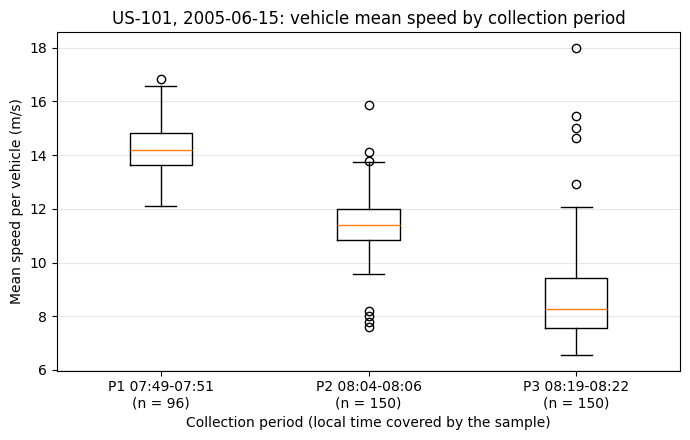

In [9]:
period_summary = pipeline.summarise_by_period(vehicles)
display(period_summary)
speed_figure = pipeline.plot_speed_by_period(vehicles, pipeline.FIGURE_DIR / "speed_by_period.png")

,n_vehicles,n_with_headway,mean_speed_mps,median_time_headway_s,q25_time_headway_s,q75_time_headway_s,median_space_headway_m
vehicle_class,,,,,,,
auto,384,371,11.06,2.04,1.63,2.46,20.81
truck,7,6,10.44,3.02,1.68,4.83,34.23
motorcycle,5,5,13.17,0.86,0.63,1.50,11.38


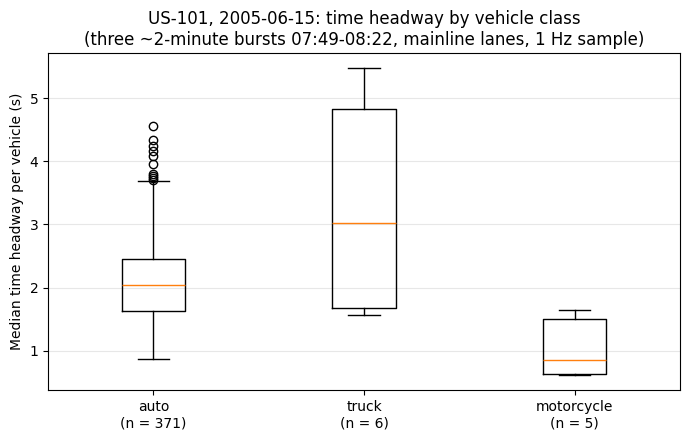

In [10]:
class_summary = pipeline.summarise_by_class(vehicles)
display(class_summary)
headway_figure = pipeline.plot_headway_by_class(vehicles, pipeline.FIGURE_DIR / "headway_by_class.png")

### Interpretation

- **Congestion builds across the morning.** Mean vehicle speed falls from about 14.3 m/s (≈ 32 mph) in the 07:49–07:51 burst to 11.4 m/s at 08:04–08:06 and 8.7 m/s at 08:19–08:22. Median spacing shrinks from about 24 m to 18 m. Median *time* headway rises from 1.7 s to 2.2 s. The two headway trends are consistent: at low speed, a shorter gap in metres still takes longer to cover.
- **Vehicle class.** Trucks have a longer median time headway (≈ 3.0 s) than autos (≈ 2.0 s), and motorcycles a much shorter one (≈ 0.9 s). The direction for trucks matches the common expectation that heavy vehicles leave more room; with 6 trucks and 5 motorcycles that have headway values, these differences may be chance.

### Why to interpret this cautiously

1. **Tiny class samples:** only 7 trucks and 5 motorcycles. The class differences are suggestive, not established.
2. **Not a representative time sample:** vehicle IDs restart in each collection period, so the filter `vehicle_id <= 150` returns the *earliest* ~2–3 minutes of each period rather than the full 15 minutes. The "trend" consists of three short snapshots on one day.
3. **One site, 2005, human drivers:** a single southbound US-101 segment cannot stand for freeways in general or for today's mixed traffic with driver assistance and automation.
4. **Measurement processing:** accelerations are clipped at ±3.41 m/s², and the 1 Hz sampling hides short manoeuvres.

## 5 Ethics Reflection

The reflection is kept in `ETHICS_REFLECTION.md` and displayed below.

In [11]:
display(Markdown((pipeline.PROJECT_DIR / "ETHICS_REFLECTION.md").read_text(encoding="utf-8")))

# Ethics Reflection — NGSIM US-101 Vehicle Trajectories

**Was the access responsible and permitted?** I used the documented Socrata API of data.transportation.gov rather than scraping or the bulk "Export" button. The dataset page requires no login, its metadata lists the license as CC BY-SA 3.0 with rights marked "public", and FHWA asks users to cite it, which I do. I did not find a stated numeric rate limit for anonymous use, so I kept the burden deliberately small: one metadata request, one count request, and three pages (five requests, one second apart, no automatic retries), with server-side filtering to one freeway, the first 150 vehicle IDs, one frame per second, and 12 of 25 columns. That is 23,793 of roughly 11.8 million rows. Raw pages are cached, so rerunning the notebook sends no further requests.

**Privacy and combination risk.** The data contain no names or plates, but they are not as anonymous as they look. Each trajectory records vehicle length, lane, and position every 0.1 s with exact timestamps, and the same portal links the original US-101 video. Matching a trajectory to its vehicle in the video, and possibly to a readable plate, is therefore plausible. The risk is modest for a 2005 morning commute, but it is not zero. I did not collect global coordinates or lateral position, and my analysis uses vehicle-level summaries. My 1 Hz frame file still keeps timestamps, lane, and length, so this reduces the risk rather than removing it.

**Who could be harmed by misuse or misinterpretation?** NGSIM is widely used to calibrate car-following and automated-vehicle safety models. My sample covers one southbound segment, three bursts of about two minutes each, and human drivers from 2005. It includes only 7 trucks and 5 motorcycles. If someone used my class comparison (for example, motorcycles' short median headway) to tune the following gaps of an automated controller, the result could be gaps that are too small. The people harmed would be other road users, especially motorcyclists, who never agreed to be modelled.

**Limitations I should communicate.** Because vehicle IDs restart in every collection period, my ID filter selects the earliest vehicles of each period. The sample is not representative of the full 15-minute periods. Accelerations are clipped at about ±3.4 m/s², and headway codes (0 and 9999.99) had to be removed. My results are descriptive and should not be read as general traffic behaviour.
